<a href="https://colab.research.google.com/github/MoutazMohamed0/DATA-205-Capstone-Project-Fall-2026/blob/main/EDA%20%26%20Ingestion/DATA205CapstoneProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the Raw FRED dataset
df1 = pd.read_csv("https://raw.githubusercontent.com/MoutazMohamed0/DATA-205-Capstone-Project-Fall-2026/refs/heads/main/Data/Raw%20Data/fredgraphannualaverage.csv")

In [3]:
# Overview (descriptive statistics) & structure of the FRED dataset
print(df1.head())
print(df1.info())
print(df1.describe())
print(df1.shape)

  observation_date  UNRATE  LNS14000003  LNS14000006  LNU04032183  LNS14000009
0         1/1/1948     3.8          NaN          NaN          NaN          NaN
1         1/1/1949     6.1          NaN          NaN          NaN          NaN
2         1/1/1950     5.2          NaN          NaN          NaN          NaN
3         1/1/1951     3.3          NaN          NaN          NaN          NaN
4         1/1/1952     3.0          NaN          NaN          NaN          NaN
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  79 non-null     object 
 1   UNRATE            78 non-null     float64
 2   LNS14000003       72 non-null     float64
 3   LNS14000006       54 non-null     float64
 4   LNU04032183       26 non-null     float64
 5   LNS14000009       52 non-null     float64
dtypes: float64(5), object(1)
memory usage: 3.8+

In [4]:
# Converting the observation date column to datetime and sorting values
df1["observation_date"] = pd.to_datetime(df1["observation_date"])
df1 = df1.sort_values("observation_date")
df1 = df1[df1["observation_date"] >= "1972-01-01"]

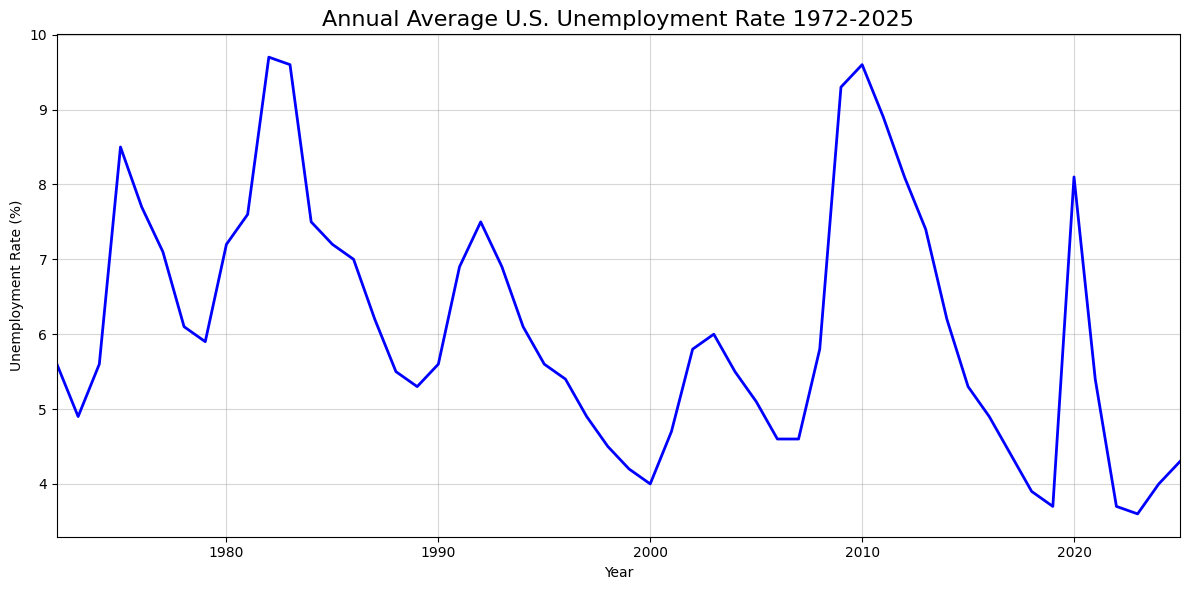

In [5]:
# Annual Average Unemployment Rate
plt.figure(figsize=(12, 6))

plt.plot(df1["observation_date"], df1["UNRATE"], color= "Blue", linewidth=2)

plt.title("Annual Average U.S. Unemployment Rate 1972-2025", fontsize=16)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.margins(x=0)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

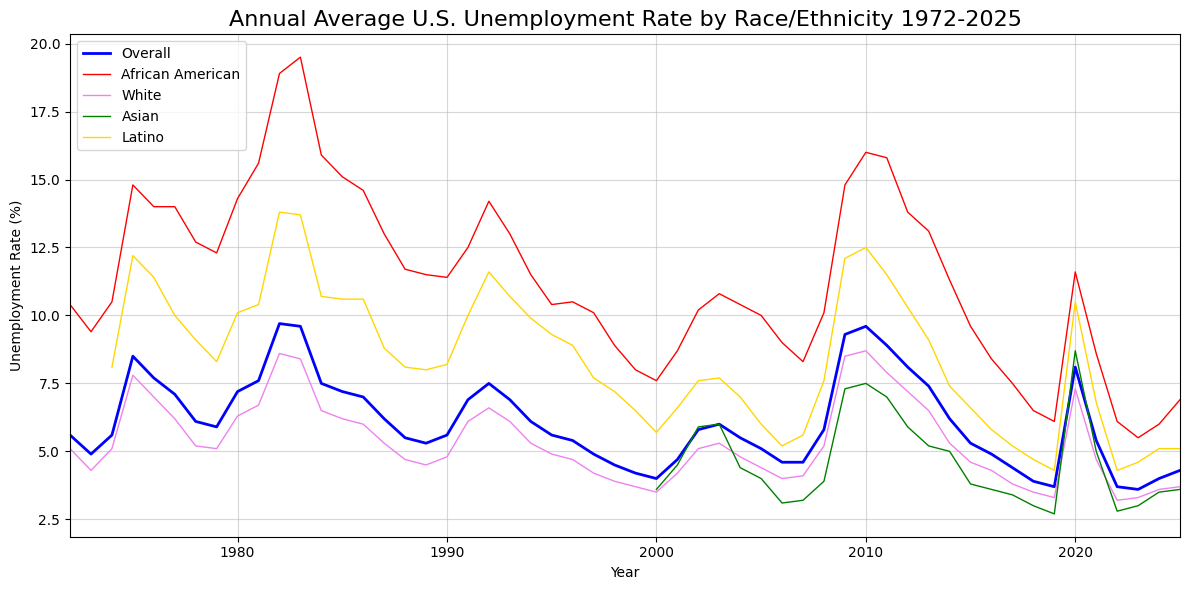

In [6]:
# Annual Average Unemployment Rate by race
plt.figure(figsize=(12, 6))

plt.plot(df1["observation_date"], df1["UNRATE"], label="Overall", color= "Blue", linewidth=2)

plt.plot(df1["observation_date"], df1["LNS14000006"], label="African American", color= "Red", linewidth=1)

plt.plot(df1["observation_date"], df1["LNS14000003"], label="White", color= "Violet", linewidth=1)

plt.plot(df1["observation_date"], df1["LNU04032183"], label="Asian", color= "Green", linewidth=1)

plt.plot(df1["observation_date"], df1["LNS14000009"], label="Latino", color= "Gold", linewidth=1)

plt.title("Annual Average U.S. Unemployment Rate by Race/Ethnicity 1972-2025", fontsize=16)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend(loc="upper left")
plt.margins(x=0)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

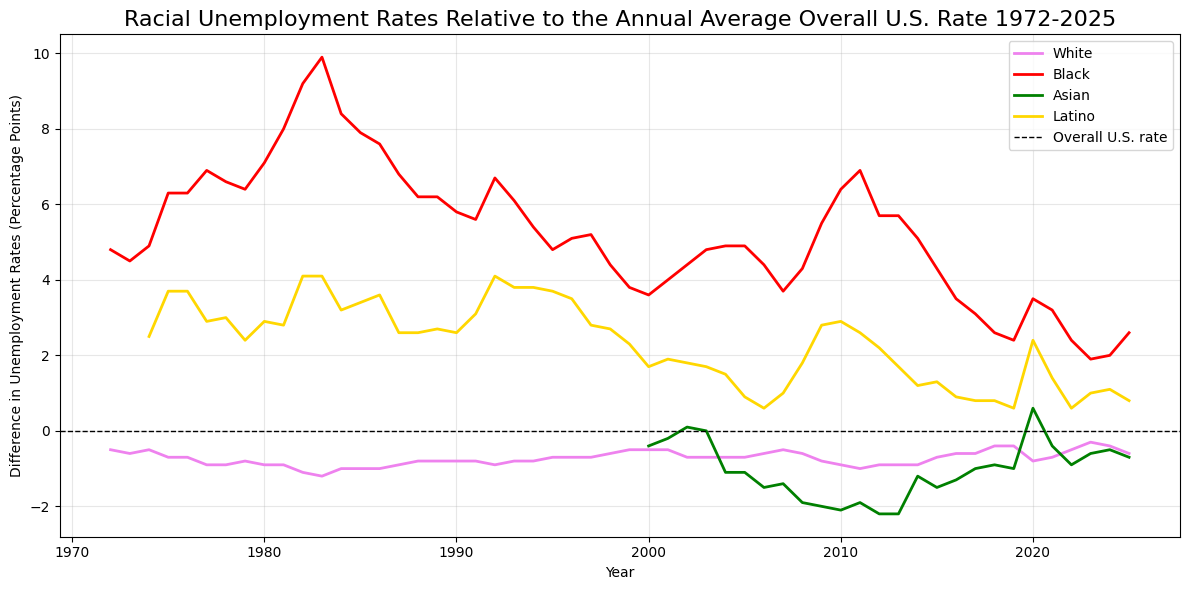

In [12]:
# Average Annual Racial Unemployment Rate relative to Overall National Unemployment Rate
plt.figure(figsize=(12, 6))

df1["White Difference"] = df1["LNS14000003"] - df1["UNRATE"]
df1["Black Difference"] = df1["LNS14000006"] - df1["UNRATE"]
df1["Hispanic Difference"] = df1["LNS14000009"] - df1["UNRATE"]
df1["Asian Difference"] = df1["LNU04032183"] - df1["UNRATE"]

plt.plot(df1["observation_date"], df1["White Difference"], label="White", color="Violet", linewidth=2)
plt.plot(df1["observation_date"], df1["Black Difference"], label="Black", color="Red", linewidth=2)
plt.plot(df1["observation_date"], df1["Asian Difference"], label="Asian", color="Green", linewidth=2)
plt.plot(df1["observation_date"], df1["Hispanic Difference"], label="Latino", color="Gold", linewidth=2)

plt.axhline(y=0, color="black", linestyle="--", linewidth=1, label="Overall U.S. rate")

plt.title("Racial Unemployment Rates Relative to the Annual Average Overall U.S. Rate 1972-2025", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Difference in Unemployment Rates (Percentage Points)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

These graphs allow for long term comparisons of overall average annual unemployment rates and unemployment rates across racial groups (White, African American, Latino, and Asian). Through much of the graph, African American and Latino unemployment rates are noticeably higher than the overall unemployment rate and those of White and Asian workers. Data availability also varies by race for example, unemployment data for Asian workers are only available beginning around 2000.

In [7]:
# Loading the Merged BLS dataset
df2 = pd.read_excel('https://raw.githubusercontent.com/MoutazMohamed0/DATA-205-Capstone-Project-Fall-2026/main/Data/Merged%20Data/MD-BLS-2000-2025.xlsx', engine='openpyxl')

In [8]:
# Overview (descriptive statistics) & structure of the merged (National & Maryland) BLS dataset
print(df2.head())
print(df2.info())
print(df2.describe())
print(df2.shape)

   Year  US UNRate Overall  US UNRate White  \
0  2000                4.0              3.5   
1  2001                4.7              4.2   
2  2002                5.8              5.1   
3  2003                6.0              5.3   
4  2004                5.5              4.8   

   US UNRate Black or African American  US UNRate Asian  \
0                                  7.6              3.6   
1                                  8.7              4.5   
2                                 10.2              5.9   
3                                 10.8              6.0   
4                                 10.4              4.4   

   US UNRate Hispanic or Latino  MD UNRate Overall  MD UNRate White  \
0                           5.7                3.9              2.7   
1                           6.6                4.1              2.9   
2                           7.6                4.4              3.1   
3                           7.7                4.5              3.6   
4      

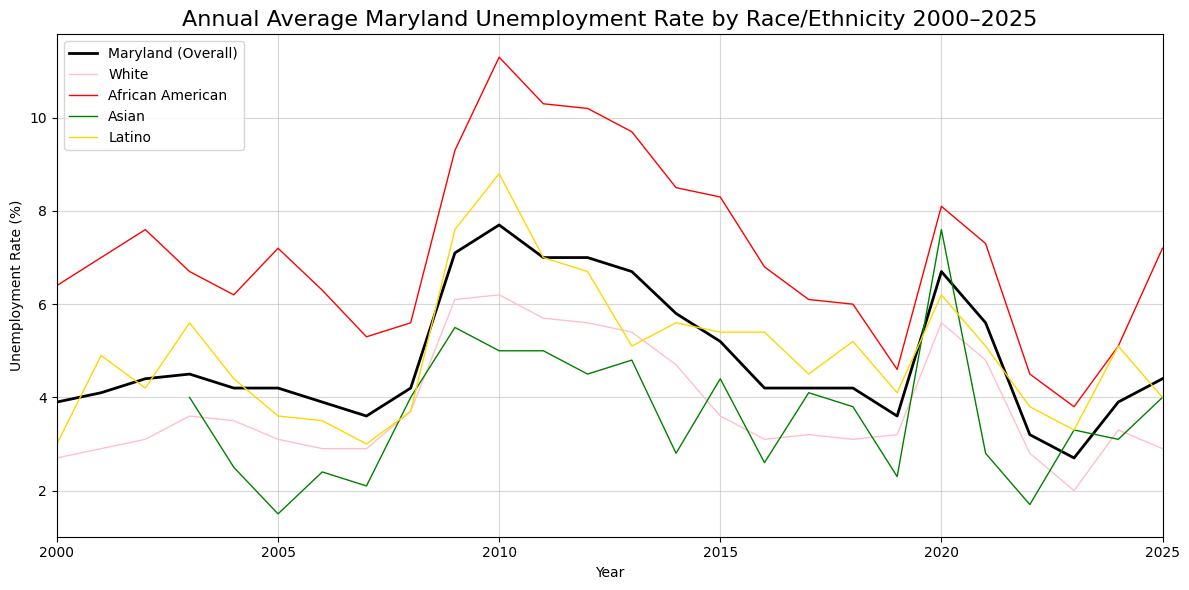

In [9]:
# Annual Average Unemployment Rate by race in Maryland
plt.figure(figsize=(12, 6))

plt.plot(df2["Year"], df2["MD UNRate Overall"], label="Maryland (Overall)", color="Black", linewidth=2)

plt.plot(df2["Year"], df2["MD UNRate White"], label="White", color="Pink", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Black or African American"], label="African American", color="Red", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Asian"], label="Asian", color="Green", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Hispanic or Latino"], label="Latino", color="Gold", linewidth=1)

plt.title("Annual Average Maryland Unemployment Rate by Race/Ethnicity 2000–2025", fontsize=16)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend(loc="upper left")
plt.margins(x=0)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

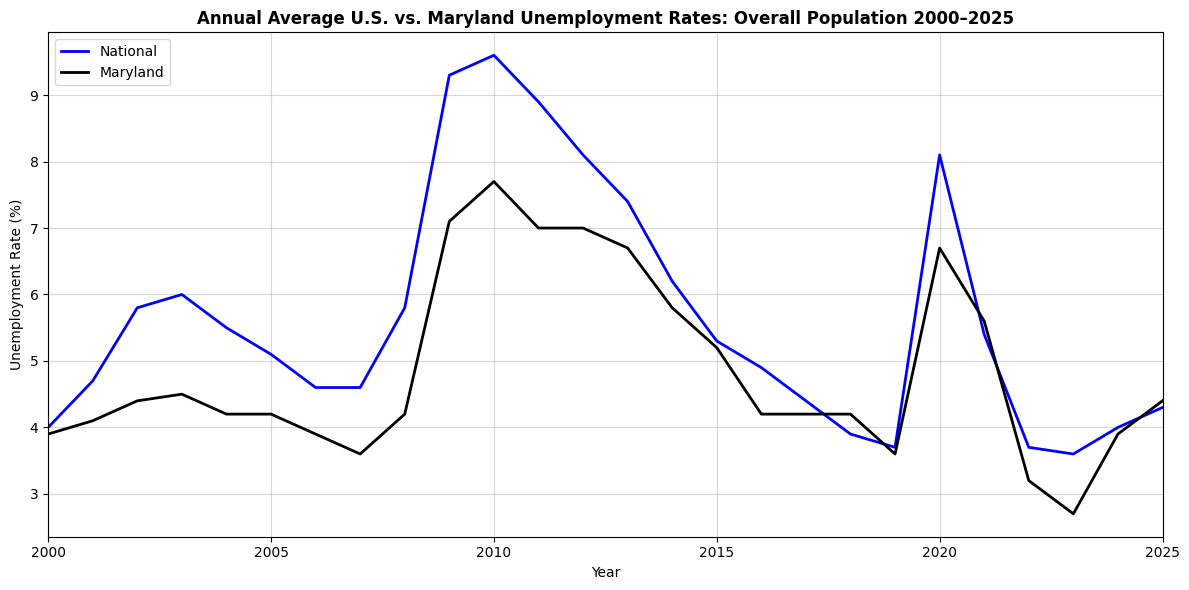

In [10]:
# Annual Average Overall US Unemployment vs. Unemployment Rate Overall in Maryland
plt.figure(figsize=(12, 6))

plt.plot(df2["Year"], df2["US UNRate Overall"], label="National", color="Blue", linewidth=2)

plt.plot(df2["Year"], df2["MD UNRate Overall"], label="Maryland", color="Black", linewidth=2)

plt.title("Annual Average U.S. vs. Maryland Unemployment Rates: Overall Population 2000–2025", fontweight='bold', fontsize=12)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend(loc="upper left")
plt.margins(x=0)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

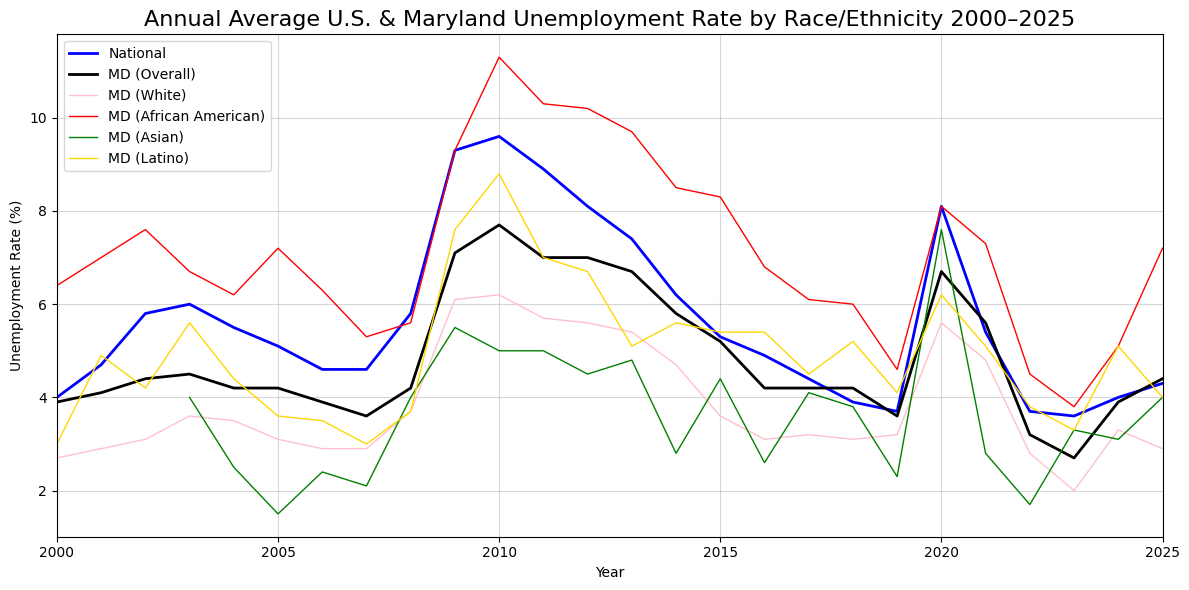

In [11]:
# Annual Average Overall US Unemployment vs. Unemployment Rate Overall and by Race in Maryland
plt.figure(figsize=(12, 6))

plt.plot(df2["Year"], df2["US UNRate Overall"], label="National", color="Blue", linewidth=2)

plt.plot(df2["Year"], df2["MD UNRate Overall"], label="MD (Overall)", color="Black", linewidth=2)

plt.plot(df2["Year"], df2["MD UNRate White"], label="MD (White)", color="Pink", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Black or African American"], label="MD (African American)", color="Red", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Asian"], label="MD (Asian)", color="Green", linewidth=1)

plt.plot(df2["Year"], df2["MD UNRate Hispanic or Latino"], label="MD (Latino)", color="Gold", linewidth=1)

plt.title("Annual Average U.S. & Maryland Unemployment Rate by Race/Ethnicity 2000–2025", fontsize=16)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend(loc="upper left")
plt.margins(x=0)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

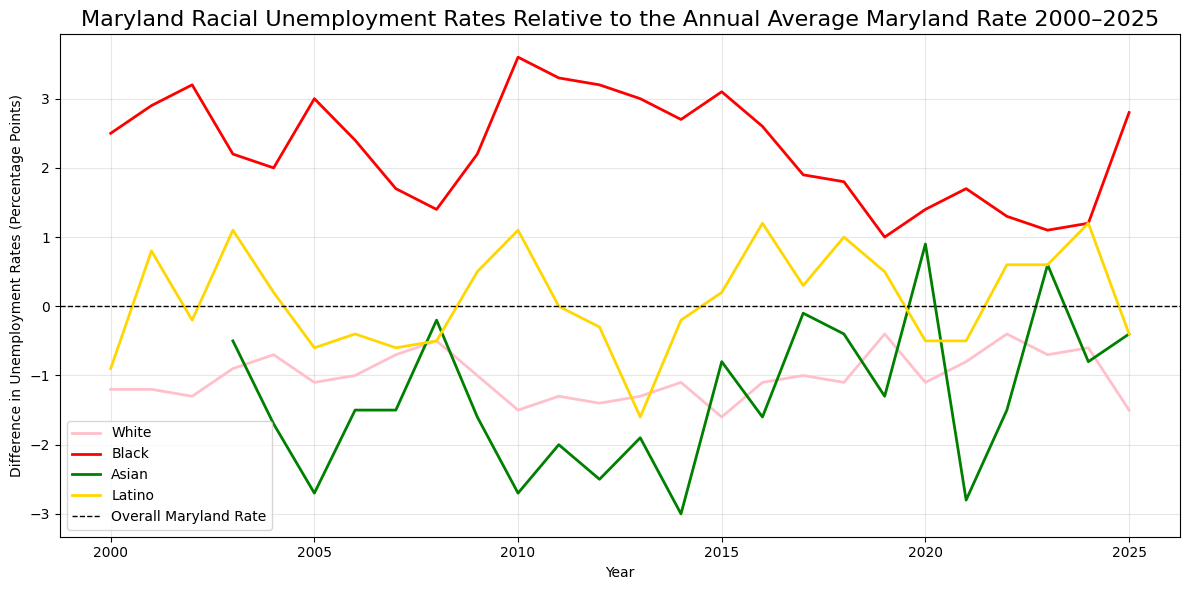

In [13]:
# Average Annual Racial Unemployment Rate in Maryland relative to Overall Maryland Unemployment Rate
plt.figure(figsize=(12, 6))

df2["White Difference"] = df2["MD UNRate White"] - df2["MD UNRate Overall"]
df2["Black Difference"] = df2["MD UNRate Black or African American"] - df2["MD UNRate Overall"]
df2["Hispanic Difference"] = df2["MD UNRate Hispanic or Latino"] - df2["MD UNRate Overall"]
df2["Asian Difference"] = df2["MD UNRate Asian"] - df2["MD UNRate Overall"]

plt.plot(df2["Year"], df2["White Difference"], label="White", color="Pink", linewidth=2)
plt.plot(df2["Year"], df2["Black Difference"], label="Black", color="Red", linewidth=2)
plt.plot(df2["Year"], df2["Asian Difference"], label="Asian", color="Green", linewidth=2)
plt.plot(df2["Year"], df2["Hispanic Difference"], label="Latino", color="Gold", linewidth=2)


plt.axhline(y=0, color="black", linestyle="--", linewidth=1, label="Overall Maryland Rate")

plt.title("Maryland Racial Unemployment Rates Relative to the Annual Average Maryland Rate 2000–2025", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Difference in Unemployment Rates (Percentage Points)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

These graphs allow for a 25 year comparison (2000-2025)  of overall average annual unemployment rates both nationally and in Maryland as well as unemployment rates across racial groups in Maryland. The national average annual unemployment rate is generally higher than Maryland's overall unemployment rate and the rates of most racial groups in Maryland. However, throughout most of the graph, African American unemployment rates in Maryland are higher than the overall unemployment rates nationally and in Maryland, as well as the rates for White, Latino, and Asian workers in Maryland.